In [ ]:
import sys; sys.path.insert(0, '../../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import seaborn as sns
from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
# from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi

from matplotlib.collections import LineCollection
from matplotlib import colors as mcolors
import scipy
import h5py

In [5]:
prefix = '/mnt/staging/'
figure_root = str(FIGURES / "figure5") + "/"

In [6]:
with h5py.File(figure_root+'histology_data_save.mat', "r") as h5f:
    # print(h5f.keys())
    dataset = np.array(h5f['data_save']).transpose((2,1,0))
    

In [7]:
print(dataset.shape)

(5207, 6578, 60)


In [8]:
y_axis_squeeze = np.max(dataset,axis=1)

In [9]:
y_axis_squeeze.shape

(5207, 60)

/home/wx2203/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:21: RuntimeWarning: divide by zero encountered in log


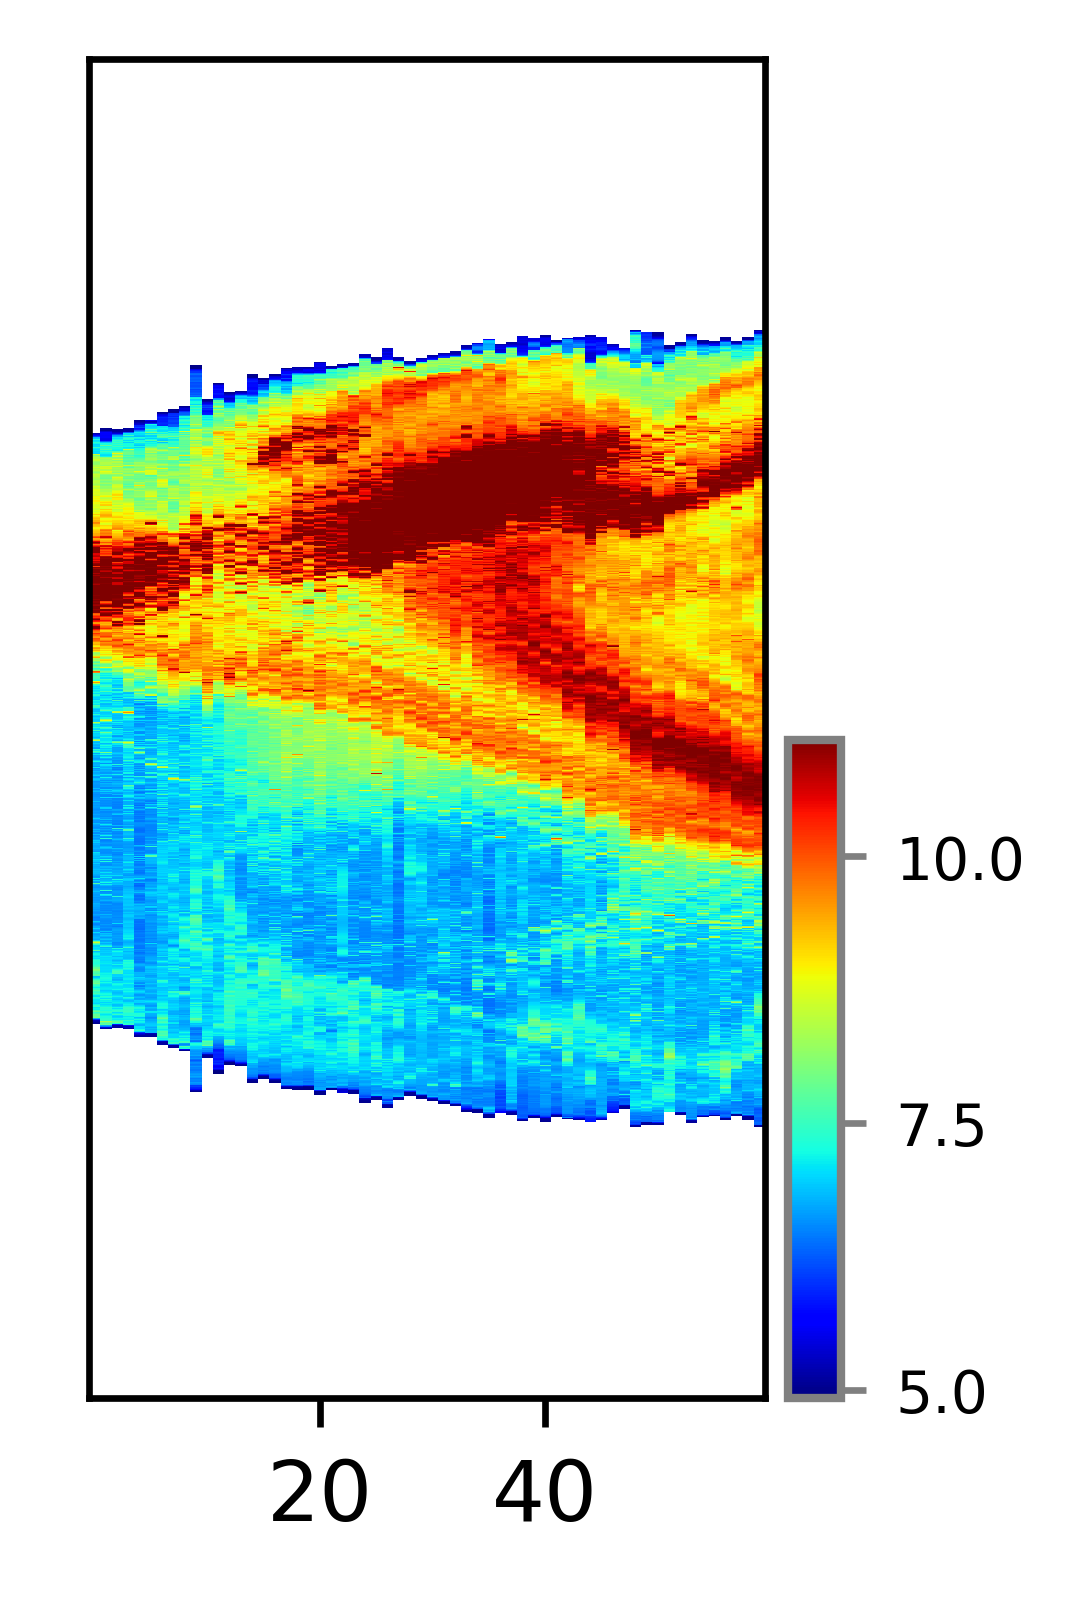

In [9]:
from matplotlib.gridspec import GridSpec
plt.style.use('default')
from matplotlib.ticker import FuncFormatter
from matplotlib import ticker
fmt = lambda x, pos: '{:.0%}'.format(x)

gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=600)

y_offset = 20;x_offset=20;


ax0 = fig.add_subplot(gs[y_offset:y_offset+10,x_offset:x_offset+5])
ax990 = fig.add_subplot(gs[y_offset+5:y_offset+10,x_offset+5:x_offset+9])


# sbp0 = sns.heatmap(mean_intensity_projection.T,vmax=2000,vmin=0,cmap='gray',ax=ax0)

sbp0 = ax0.imshow(np.log(y_axis_squeeze),cmap='jet',aspect='auto',interpolation='nearest')


ax0.set_yticks([])
ax0.set_xticks([20,40])
        
# ax0.axhline(32)

cb = fig.colorbar(sbp0, cax=ax990,fraction=0.5,orientation='vertical');
cb.ax.tick_params(labelsize=7,length=3,color='gray')
cb.ax.yaxis.tick_right()       
cb.outline.set_edgecolor('gray')
cb.outline.set_linewidth(1)
tick_locator = ticker.MaxNLocator(nbins=3)
cb.locator = tick_locator
cb.update_ticks()
ax990.set_aspect(2)
ax990.set_anchor('W')

plt.savefig('fig5-csn_MIP_side_view.svg',format='svg',dpi=300)


# Fig. 5c: CSN max intensity projection (dorsal view), registered to the Allen CCF

The GFP (CSN) stack loaded above (`dataset`, 60 coronal sections, 2 µm/px, 50 µm apart) is registered section by
section to the Allen Mouse Brain CCFv3 at 25 µm (`allen_mouse_25um` v1.2 from BrainGlobe), then projected dorsally.

**Registration** (per-section fits in `FIGURES/figure5/transforms.json`). Each section's DAPI channel was downsampled
to 25 µm and fitted to the CCF reference image at its AP position with a 2D affine transform (translation, rotation,
separate x/y scale; Powell search maximising normalised cross-correlation inside the atlas brain mask; bounds
±50 voxels, ±0.15 rad, 0.8–1.2 scale). Sections were placed every 2 voxels (50 µm) from AP voxel 129, where the first
detected CSN somata fall in CCF space, to voxel 247. `transforms.json` stores, for every section, its AP voxel, the
fitted parameters and the final correlation.

**Projection.** The fitted transforms are applied to the GFP channel; consecutive sections are linearly interpolated
to fill the 1-voxel gap between them. Voxels outside the CCF brain annotation are set to zero, the volume is cropped
to the dorsal slab (DV voxels 64–176, i.e. raw rows 800–2200) and max-projected along DV. The projection is then
resampled into the `atlas.mat` dorsal-view grid (540 × 540 px, 50.79 px/mm, bregma at pixel (270, 270), bregma = CCF
AP voxel 220) and drawn with the dorsal-view area contours of `atlas.mat`; areas outside the imaged slab are greyed out.

The region-name legend and the colorbar label (`count`, ×10⁴) in the published panel were added in Illustrator.

In [ ]:
# ── inputs ──
TRANSFORMS_JSON = str(FIGURES / "figure5" / "transforms.json")   # per-section affine fits (see above)
ABA_DATA_ROOT = str(FIGURES / "figure5") + "/"                    # atlas.mat (dorsal-view areas)
PALATTE_DICT_PATH = str(PREPARES / "config") + "/palatte_dict"
# Allen CCFv3 annotation at 25 µm, from the BrainGlobe cache. Download it once with
#   python -c "from brainglobe_atlasapi import BrainGlobeAtlas; BrainGlobeAtlas('allen_mouse_25um')"
# or point BRAINGLOBE_ATLAS_DIR at a copy of the atlas folder.
import os
from pathlib import Path
BRAINGLOBE_ATLAS_DIR = Path(os.environ.get('BRAINGLOBE_ATLAS_DIR',
                                           Path.home() / '.brainglobe' / 'allen_mouse_25um_v1.2'))

FIG5C_CMAP = 'magma'          # colormap of the projection (a matplotlib name, or a pickled colormap in PREPARES/config)
FIG5C_VMAX = 40000            # colour scale, GFP counts

# ── geometry ──
PIXEL_SIZE_XY_UM = 2.0                                  # raw histology pixel size
ATLAS_RES_UM = 25.0                                     # CCF voxel size
DOWNSAMPLE_FACTOR = ATLAS_RES_UM / PIXEL_SIZE_XY_UM     # 12.5
SECTION_STEP_VOXELS = 50.0 / ATLAS_RES_UM               # 50 µm sections = 2 CCF voxels
N_SLICES = 60
AP_START = 129                                          # CCF AP voxel of section 0 (see above)
AP_END = AP_START + int((N_SLICES - 1) * SECTION_STEP_VOXELS)   # 247
BREGMA_AP_VOXEL = 220                                   # bregma in CCF 25 µm AP voxels

MIP_DV_RAW_START, MIP_DV_RAW_END = 800, 2200            # dorsal slab, raw pixel rows
MIP_DV_START = int(MIP_DV_RAW_START / DOWNSAMPLE_FACTOR)        # 64 CCF voxels
MIP_DV_END = int(MIP_DV_RAW_END / DOWNSAMPLE_FACTOR)            # 176

SLICE_1_IDX, SLICE_33_IDX = 0, 32                       # sections marked on the panel ("slice #1", "slice #33")

PIXELS_PER_MM = 50.79                                   # atlas.mat dorsal-view grid
ATLAS_MAT_SIZE = 540

In [ ]:
import json
import tifffile
import matplotlib
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator
from matplotlib.gridspec import GridSpec
from scipy.ndimage import zoom, binary_fill_holes, binary_erosion
from skimage.transform import AffineTransform, warp
from skimage.measure import find_contours
from skimage.morphology import disk

def resolve_cmap(name):
    # a pickled colormap in PREPARES/config if there is one, else a matplotlib builtin
    p = Path(str(PREPARES / 'config')) / name
    return load_pickle(str(p)) if p.exists() else plt.get_cmap(name)

def downsample_section(img, factor):
    return zoom(img.astype(np.float32), 1.0 / factor, order=1)

def apply_affine_2d(img, tx, ty, rotation, scale_x, scale_y, output_shape):
    # the transform fitted during registration: centre -> scale -> rotate -> output centre + (tx, ty)
    center_y, center_x = img.shape[0] / 2, img.shape[1] / 2
    out_cy, out_cx = output_shape[0] / 2, output_shape[1] / 2
    full = (AffineTransform(translation=(-center_x, -center_y)) + AffineTransform(scale=(scale_x, scale_y))
            + AffineTransform(rotation=rotation) + AffineTransform(translation=(out_cx + tx, out_cy + ty)))
    return warp(img, full.inverse, output_shape=output_shape, order=1, preserve_range=True)

# Allen area colours: the palette used throughout the paper, with the same derived keys as the cells above
palatte_dict = load_pickle(PALATTE_DICT_PATH)
palatte_dict['mouth'] = palatte_dict['RM']
palatte_dict['nose'] = palatte_dict['RN']
palatte_dict['LV'] = '#cd80a1'
palatte_dict['tail'] = 'palegreen'
palatte_dict['LT'] = '#b3b3b3'
palatte_dict['RT'] = '#b69d76'
dict_color_matching = {
    'SSp_tr':  palatte_dict['RT'],
    'SSp_n':   palatte_dict['RN'],
    'SSp_bfd': palatte_dict['RW'],
    'SSp_ll':  palatte_dict['RHP'],
    'SSp_m':   palatte_dict['RM'],
    'VIS':     palatte_dict['RV'],
    'RSP':     palatte_dict['RSP'],
    'SSp_ul':  palatte_dict['RFP'],
    'MOp':     'lightgray',
    'MOs':     'darkgray',
    'SSs':     'darkslategray',
}

**Registered GFP volume** (CCF space, 528 AP × 320 DV × 456 LR voxels)

In [ ]:
ann = tifffile.imread(BRAINGLOBE_ATLAS_DIR / 'annotation.tiff')    # (528, 320, 456) CCF region IDs
atlas_shape = ann.shape
coronal_shape = atlas_shape[1:]                                     # (DV, LR)

with open(TRANSFORMS_JSON) as f:
    transforms = {t['section']: t for t in json.load(f)}

def warped_section(i):
    t = transforms[i]
    return apply_affine_2d(downsample_section(dataset[:, :, i], DOWNSAMPLE_FACTOR),
                           t['tx'], t['ty'], t['rotation'], t['scale_x'], t['scale_y'], coronal_shape)

vol_sum = np.zeros(atlas_shape)
vol_count = np.zeros(atlas_shape)
step = int(SECTION_STEP_VOXELS)
for i in range(N_SLICES):
    if i not in transforms:
        continue
    ap_idx = transforms[i]['ap_voxel']
    warped = warped_section(i)
    vol_sum[ap_idx] += warped
    vol_count[ap_idx] += warped > 0
    # fill the AP voxels between this section and the next by linear interpolation
    if step > 1 and i + 1 in transforms:
        warped_next = warped_section(i + 1)
        for j in range(1, step):
            if ap_idx + j < atlas_shape[0]:
                interp = (1 - j / step) * warped + (j / step) * warped_next
                vol_sum[ap_idx + j] += interp
                vol_count[ap_idx + j] += interp > 0

vol = np.divide(vol_sum, vol_count, out=np.zeros(atlas_shape), where=vol_count > 0).astype(np.float32)
del vol_sum, vol_count
print('registered volume', vol.shape, '| non-zero voxels:', np.count_nonzero(vol))

registered volume (528, 320, 456) | non-zero voxels: 8696385


**Dorsal max intensity projection**, resampled into the `atlas.mat` dorsal-view grid

In [ ]:
dv_start, dv_end = max(0, MIP_DV_START), min(atlas_shape[1], MIP_DV_END)
brain_dv = ann[:, dv_start:dv_end, :] > 0                          # CCF brain voxels in the dorsal slab
vol_slab = np.where(brain_dv, vol[:, dv_start:dv_end, :], 0)
dorsal_mip = np.max(vol_slab, axis=1)                               # (AP, LR)
in_slab = np.zeros(atlas_shape[0], bool)
in_slab[AP_START:AP_END + 2] = True                                 # imaged AP range (last section + its gap)
dorsal_mip[~in_slab, :] = np.nan
dorsal_mip[~np.any(brain_dv, axis=1)] = np.nan
del ann, vol_slab
print('DV slab: CCF voxels %d-%d | MIP range %.1f-%.1f' % (dv_start, dv_end, np.nanmin(dorsal_mip), np.nanmax(dorsal_mip)))

# atlas.mat pixel (row, col) -> mm from bregma: x = (col - 270) / ppm, y = (270 - row) / ppm
# mm -> CCF voxel: AP = BREGMA_AP_VOXEL - y / 0.025, LR = x / 0.025 + 228; nearest voxel
rows, cols = np.mgrid[:ATLAS_MAT_SIZE, :ATLAS_MAT_SIZE]
x_mm = (cols - 270) / PIXELS_PER_MM
y_mm = (ATLAS_MAT_SIZE - rows - 270) / PIXELS_PER_MM
ap_i = np.round(BREGMA_AP_VOXEL - y_mm / (ATLAS_RES_UM / 1000)).astype(int)
lr_i = np.round(x_mm / (ATLAS_RES_UM / 1000) + atlas_shape[2] / 2).astype(int)
inside = (ap_i >= 0) & (ap_i < atlas_shape[0]) & (lr_i >= 0) & (lr_i < atlas_shape[2])
mip_atlas = np.full((ATLAS_MAT_SIZE, ATLAS_MAT_SIZE), np.nan)
mip_atlas[inside] = dorsal_mip[ap_i[inside], lr_i[inside]]
print('resampled to', mip_atlas.shape, '| valid pixels:', np.count_nonzero(~np.isnan(mip_atlas)))

DV slab: CCF voxels 64-176 | MIP range 0.0-65238.7
resampled to (540, 540) | valid pixels: 67402


**Dorsal-view Allen area contours** (`atlas.mat`), coloured by body part

In [ ]:
atlas_mat = sio.loadmat(ABA_DATA_ROOT + 'atlas.mat')
atlas = atlas_mat['atlas'].astype(float)
atlas[atlas == 0] = np.nan
atlas[np.abs(atlas) == 301] = np.nan                                # remove the olfactory bulb
areas = np.unique(atlas[~np.isnan(atlas)]).astype(int)
areas = areas[areas > -1000]

def parse_areanames(areanames_):
    areainds = [a[0][0] for a in areanames_[0][0]]
    names = [areanames_[0][0].dtype.descr[i][0] for i in range(len(areainds))]
    order = np.argsort(np.abs(areainds))
    return [areainds[i] for i in order], [names[i] for i in order]

areainds, areanames_all = parse_areanames(atlas_mat['areanames'])
dict_ind_area = {areanames_all[areainds.index(a)]: a for a in areas}

# each area takes the colour of the first matching key in dict_color_matching; others are outlined in black
color_dict = {name: next((c for key, c in dict_color_matching.items() if key in name), 'black') for name in dict_ind_area}
simplified_color_dict = {}
for name, c in color_dict.items():
    simplified_color_dict.setdefault(c, []).append(name)

dict_contours = {}
for c, names in simplified_color_dict.items():
    region = np.zeros((ATLAS_MAT_SIZE, ATLAS_MAT_SIZE))
    for name in names:
        region += atlas == dict_ind_area[name]
    region = binary_erosion(binary_fill_holes(region > 0.2), disk(2))
    contours = [ct for ct in find_contours(region, 0.8) if len(ct) > 50]
    if contours:
        dict_contours[c] = contours
print('%d areas in %d colour groups' % (len(dict_ind_area), len(simplified_color_dict)))

x_axis = np.linspace(-270, ATLAS_MAT_SIZE - 270 - 1, ATLAS_MAT_SIZE) / PIXELS_PER_MM
y_axis = np.linspace(ATLAS_MAT_SIZE - 270 - 1, -270, ATLAS_MAT_SIZE) / PIXELS_PER_MM
extent_allen = [x_axis[0], x_axis[-1], y_axis[-1], y_axis[0]]
ap_mm = lambda s: (BREGMA_AP_VOXEL - (AP_START + s * SECTION_STEP_VOXELS)) * ATLAS_RES_UM / 1000   # + = anterior
slice1_mm, slice33_mm = ap_mm(SLICE_1_IDX), ap_mm(SLICE_33_IDX)
print('slice #1: %+.2f mm, slice #33: %+.2f mm from bregma' % (slice1_mm, slice33_mm))

64 areas in 12 colour groups
slice #1: +2.27 mm, slice #33: +0.68 mm from bregma


# save a figure

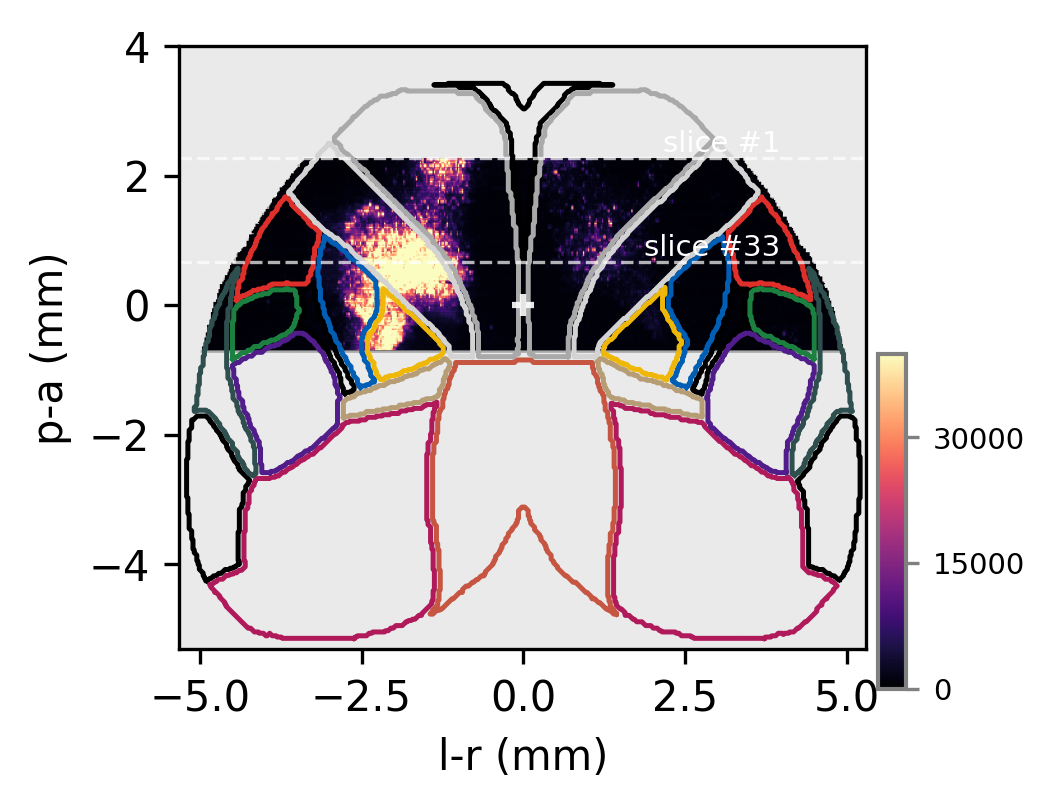

In [ ]:
plt.style.use('default')
plt.rcParams['svg.fonttype'] = 'none'
gs = GridSpec(100, 100)
fig = plt.figure(figsize=(30, 30), dpi=300)
y_offset = 20; x_offset = 20; x_width = 10
ax0 = fig.add_subplot(gs[y_offset:y_offset + 10, x_offset:x_offset + x_width])
ax990 = fig.add_subplot(gs[y_offset + 5:y_offset + 10, x_offset + x_width:x_offset + x_width + 2])

sbp0 = ax0.imshow(mip_atlas, cmap=resolve_cmap(FIG5C_CMAP), aspect='auto', vmin=0, vmax=FIG5C_VMAX, extent=extent_allen)
for c, contours in dict_contours.items():
    for ct in contours:
        ax0.plot((ct[:, 1] - 270) / PIXELS_PER_MM, (ATLAS_MAT_SIZE - ct[:, 0] - 270) / PIXELS_PER_MM,
                 linewidth=1.2, color=c)

# grey out everything outside the imaged slab
c_full = matplotlib.colors.colorConverter.to_rgba('#e3e3e3', alpha=1)
c_part = matplotlib.colors.colorConverter.to_rgba('#e3e3e3', alpha=0.75)
cmap_nodata = LinearSegmentedColormap.from_list('nodata', [c_part, c_part, c_full], 5120)
no_data = (np.nan_to_num(mip_atlas, nan=0) == 0).astype(float)
no_data[no_data == 0] = np.nan
ax0.imshow(no_data, cmap=cmap_nodata, extent=extent_allen)

ax0.scatter(0, 0, s=30, marker='+', color='white', alpha=0.9, zorder=9999)          # bregma
for y_, label in ((slice1_mm, 'slice #1'), (slice33_mm, 'slice #33')):
    ax0.axhline(y_, color='white', linewidth=0.8, linestyle='--', alpha=0.7)
    ax0.annotate(label, xy=(x_axis[-1] * 0.75, y_), fontsize=7, color='white', ha='right', va='bottom')
ax0.set_ylim([-5.31, 4])
ax0.set_xlabel('l-r (mm)')
ax0.set_ylabel('p-a (mm)')

cb = fig.colorbar(sbp0, cax=ax990, fraction=0.5, orientation='vertical')
cb.ax.tick_params(labelsize=7, length=3, color='gray')
cb.ax.yaxis.tick_right()
cb.outline.set_edgecolor('gray')
cb.outline.set_linewidth(1)
cb.locator = MaxNLocator(nbins=3)
cb.update_ticks()
ax990.set_aspect(0.0003)
ax990.set_anchor('W')

plt.savefig('fig5c-Allen-CSN-MIP.svg', format='svg', dpi=300, bbox_inches='tight')
plt.show()